# SEN1Floods11 — Exploratory Data Analysis

This notebook explores the hand-labeled subset of SEN1Floods11:
446 Sentinel-1 SAR chips across 11 flood events on 5 continents.

**Sections**
1. Dataset overview — splits and chip counts
2. Sample chip visualisation — VV, VH bands and flood masks
3. Backscatter distributions — flooded vs. non-flooded pixels
4. Class imbalance — flood pixel fraction per split and per region
5. Geographic distribution — chips and flood rates by event

In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import rasterio
import matplotlib.pyplot as plt
from tqdm import tqdm

DATA_DIR = Path("../data/raw")
S1_DIR   = DATA_DIR / "S1Hand"
LAB_DIR  = DATA_DIR / "LabelHand"

TRAIN_CSV   = DATA_DIR / "flood_train_data.csv"
VAL_CSV     = DATA_DIR / "flood_valid_data.csv"
TEST_CSV    = DATA_DIR / "flood_test_data.csv"
BOLIVIA_CSV = DATA_DIR / "flood_bolivia_data.csv"

plt.rcParams["figure.dpi"] = 120
plt.rcParams["font.size"] = 10

## 1. Dataset Overview

In [2]:
def load_csv(path):
    df = pd.read_csv(path, header=None, names=["s1", "label"])
    df["region"] = df["s1"].str.split("_").str[0]
    df["chip_id"] = df["s1"].str.replace("_S1Hand.tif", "", regex=False)
    return df

splits = {
    "train":   load_csv(TRAIN_CSV),
    "val":     load_csv(VAL_CSV),
    "test":    load_csv(TEST_CSV),
    "bolivia": load_csv(BOLIVIA_CSV),
}
all_chips = pd.concat(splits.values(), keys=splits.keys()).reset_index(level=0).rename(columns={"level_0": "split"})

print("Split sizes")
print("-" * 30)
for name, df in splits.items():
    print(f"  {name:<10} {len(df):>4} chips   regions: {sorted(df['region'].unique())}")
print(f"  {'TOTAL':<10} {len(all_chips):>4} chips")

Split sizes
------------------------------
  train       252 chips   regions: ['Ghana', 'India', 'Mekong', 'Nigeria', 'Pakistan', 'Paraguay', 'Somalia', 'Spain', 'Sri-Lanka', 'USA']
  val          89 chips   regions: ['Ghana', 'India', 'Mekong', 'Nigeria', 'Pakistan', 'Paraguay', 'Somalia', 'Spain', 'Sri-Lanka', 'USA']
  test         90 chips   regions: ['Ghana', 'India', 'Mekong', 'Nigeria', 'Pakistan', 'Paraguay', 'Somalia', 'Spain', 'Sri-Lanka', 'USA']
  bolivia      15 chips   regions: ['Bolivia']
  TOTAL       446 chips


In [3]:
region_counts = all_chips.groupby(["region", "split"]).size().unstack(fill_value=0)
region_counts["total"] = region_counts.sum(axis=1)
print("\nChips per region and split")
print(region_counts.sort_values("total", ascending=False).to_string())


Chips per region and split
split      bolivia  test  train  val  total
region                                     
USA              0    14     41   14     69
India            0    14     40   14     68
Paraguay         0    14     39   14     67
Ghana            0    11     31   11     53
Sri-Lanka        0     9     24    9     42
Mekong           0     6     18    6     30
Spain            0     6     18    6     30
Pakistan         0     6     16    6     28
Somalia          0     6     15    5     26
Nigeria          0     4     10    4     18
Bolivia         15     0      0    0     15


## 2. Sample Chip Visualisation

Each chip shown as: **VV band | VH band | Flood mask**

SAR backscatter is displayed in dB. Dark areas in SAR imagery indicate smooth water surfaces (low backscatter), which typically corresponds to flooded areas.

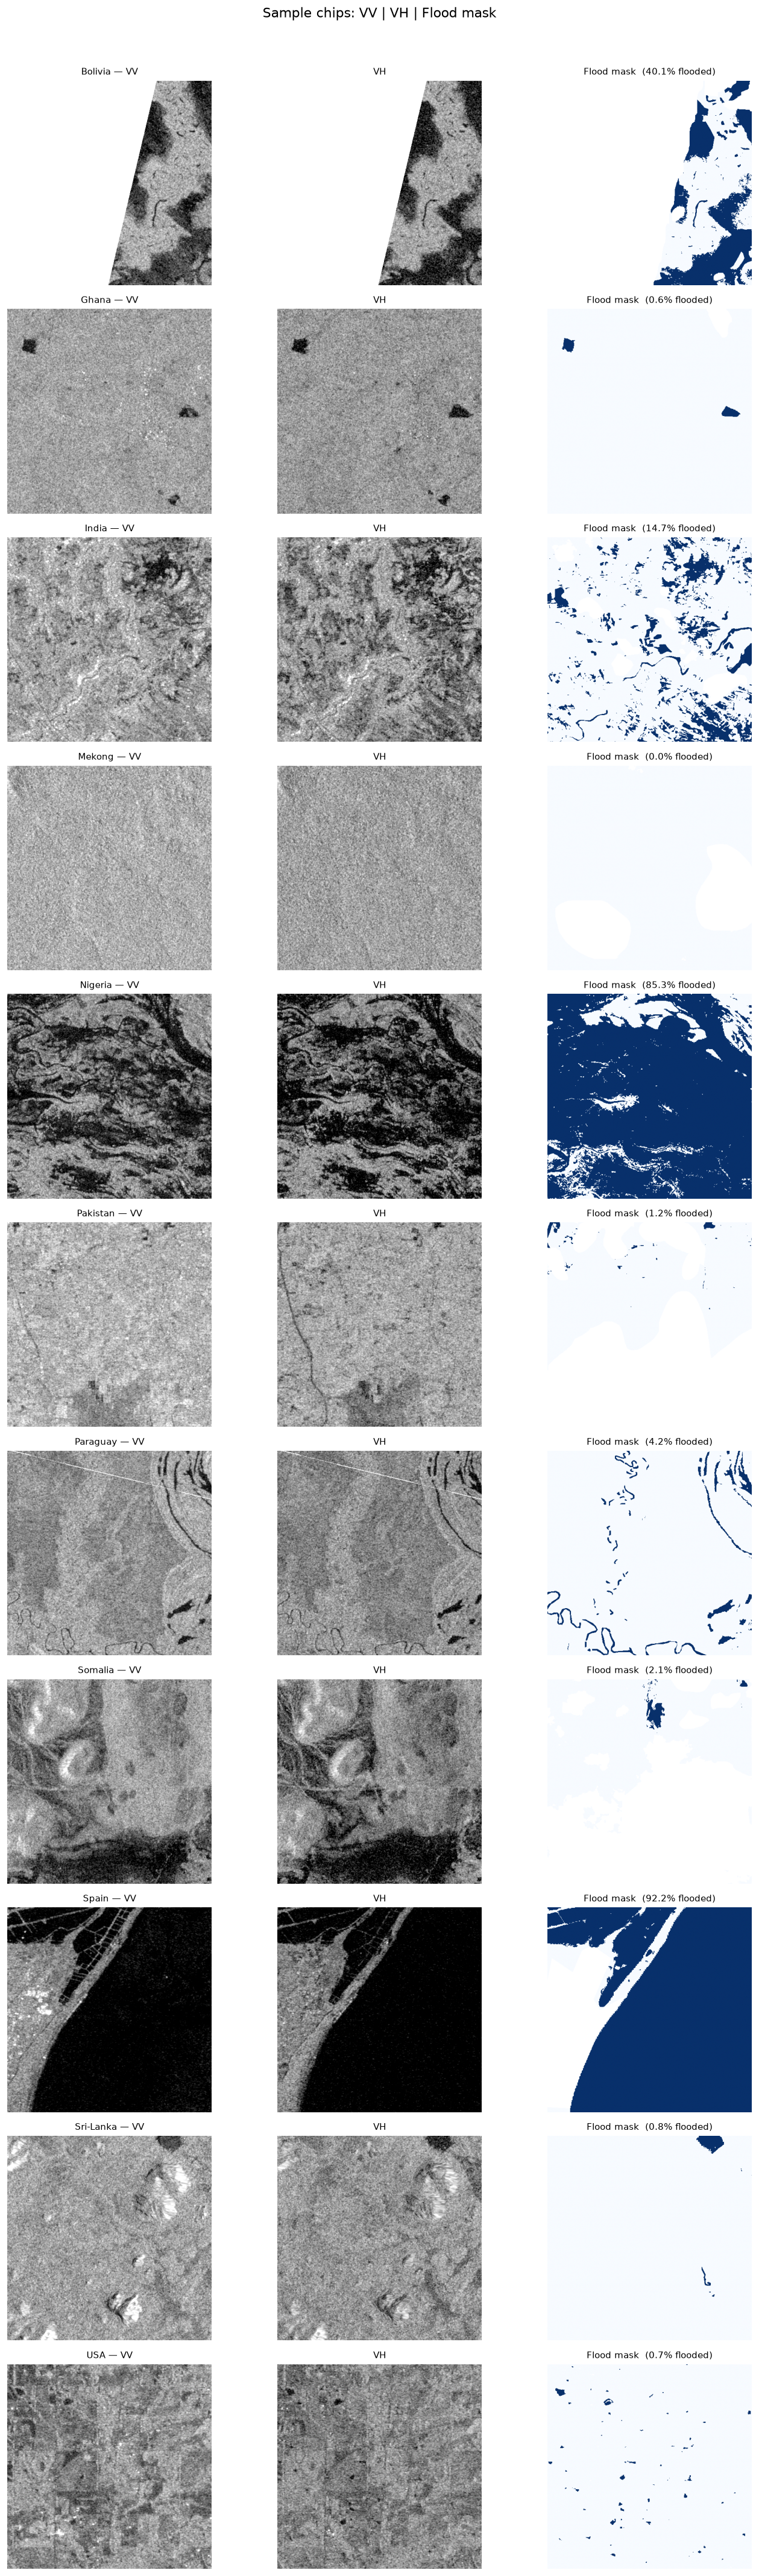

Saved to data/sample_chips.png


In [4]:
def load_chip(chip_id):
    with rasterio.open(S1_DIR / f"{chip_id}_S1Hand.tif") as src:
        sar = src.read().astype(np.float32)   # (2, H, W): VV, VH in dB
    with rasterio.open(LAB_DIR / f"{chip_id}_LabelHand.tif") as src:
        mask = src.read(1).astype(np.float32) # (H, W)
    sar  = np.nan_to_num(sar,  nan=np.nan)
    mask = np.where(mask == -1, np.nan, mask)  # nodata -> NaN
    return sar, mask

# Pick one chip per region (first in train set, else any)
regions = sorted(all_chips["region"].unique())
sample_ids = []
for r in regions:
    sub = all_chips[all_chips["region"] == r]
    sample_ids.append(sub.iloc[0]["chip_id"])

n = len(sample_ids)
fig, axes = plt.subplots(n, 3, figsize=(12, n * 3.2))
fig.suptitle("Sample chips: VV | VH | Flood mask", fontsize=13, y=1.01)

vv_kw  = dict(cmap="gray", vmin=-25, vmax=0)
vh_kw  = dict(cmap="gray", vmin=-30, vmax=-5)
mask_kw = dict(cmap="Blues", vmin=0, vmax=1)

for row, (chip_id, region) in enumerate(zip(sample_ids, regions)):
    sar, mask = load_chip(chip_id)
    flood_pct = np.nanmean(mask) * 100

    axes[row, 0].imshow(sar[0], **vv_kw)
    axes[row, 0].set_title(f"{region} — VV", fontsize=9)

    axes[row, 1].imshow(sar[1], **vh_kw)
    axes[row, 1].set_title(f"VH", fontsize=9)

    axes[row, 2].imshow(mask, **mask_kw)
    axes[row, 2].set_title(f"Flood mask  ({flood_pct:.1f}% flooded)", fontsize=9)

    for ax in axes[row]:
        ax.axis("off")

plt.tight_layout()
plt.savefig("../data/sample_chips.png", bbox_inches="tight")
plt.show()
print("Saved to data/sample_chips.png")

## 3. Backscatter Distributions

SAR backscatter should differ between flooded and non-flooded land:
open water reflects radar energy away from the sensor (low backscatter / dark pixels).
This is the physical basis for flood detection.

In [5]:
# Sample pixels from the training set to build histograms
N_CHIPS = 80  # fast enough on CPU
train_df = splits["train"].sample(min(N_CHIPS, len(splits["train"])), random_state=42)

vv_flood, vv_dry = [], []
vh_flood, vh_dry = [], []

for _, row in tqdm(train_df.iterrows(), total=len(train_df), desc="Sampling pixels"):
    sar, mask = load_chip(row["chip_id"])
    valid = ~np.isnan(mask)
    flood_px = mask[valid] == 1

    vv = sar[0][valid]
    vh = sar[1][valid]

    # Subsample to keep memory manageable
    idx = np.random.choice(len(vv), size=min(500, len(vv)), replace=False)
    vv_flood.extend(vv[idx][flood_px[idx]].tolist())
    vv_dry.extend(vv[idx][~flood_px[idx]].tolist())
    vh_flood.extend(vh[idx][flood_px[idx]].tolist())
    vh_dry.extend(vh[idx][~flood_px[idx]].tolist())

vv_flood, vv_dry = np.array(vv_flood), np.array(vv_dry)
vh_flood, vh_dry = np.array(vh_flood), np.array(vh_dry)

print(f"Sampled {len(vv_flood):,} flooded pixels and {len(vv_dry):,} non-flooded pixels")

Sampling pixels:   0%|          | 0/80 [00:00<?, ?it/s]

Sampled 3,200 flooded pixels and 36,800 non-flooded pixels


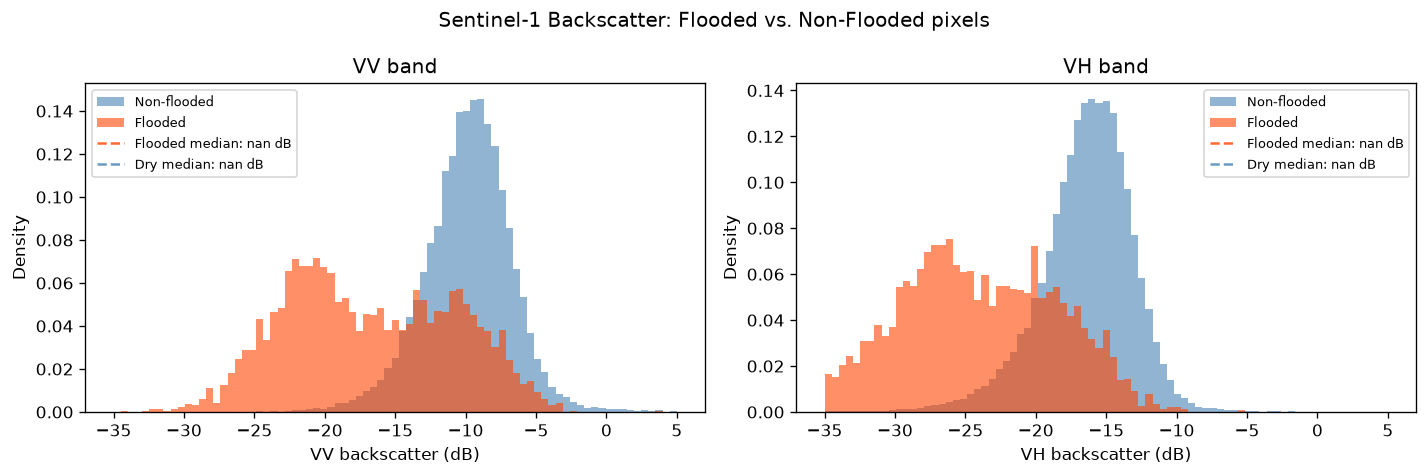

VV  — flooded median: nan dB  |  non-flooded median: nan dB  |  separation: nan dB
VH  — flooded median: nan dB  |  non-flooded median: nan dB  |  separation: nan dB


In [6]:
bins = np.linspace(-35, 5, 80)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
fig.suptitle("Sentinel-1 Backscatter: Flooded vs. Non-Flooded pixels")

for ax, (flood, dry, band) in zip(axes, [
    (vv_flood, vv_dry, "VV"),
    (vh_flood, vh_dry, "VH"),
]):
    ax.hist(dry,   bins=bins, density=True, alpha=0.6, color="steelblue", label="Non-flooded")
    ax.hist(flood, bins=bins, density=True, alpha=0.6, color="orangered",  label="Flooded")
    ax.set_xlabel(f"{band} backscatter (dB)")
    ax.set_ylabel("Density")
    ax.set_title(f"{band} band")
    ax.legend()
    ax.axvline(np.median(flood), color="orangered",  ls="--", alpha=0.8, label=f"Flooded median: {np.median(flood):.1f} dB")
    ax.axvline(np.median(dry),   color="steelblue", ls="--", alpha=0.8, label=f"Dry median: {np.median(dry):.1f} dB")
    ax.legend(fontsize=8)

plt.tight_layout()
plt.savefig("../data/backscatter_distributions.png", bbox_inches="tight")
plt.show()

print(f"VV  — flooded median: {np.median(vv_flood):.2f} dB  |  non-flooded median: {np.median(vv_dry):.2f} dB  |  separation: {np.median(vv_dry)-np.median(vv_flood):.2f} dB")
print(f"VH  — flooded median: {np.median(vh_flood):.2f} dB  |  non-flooded median: {np.median(vh_dry):.2f} dB  |  separation: {np.median(vh_dry)-np.median(vh_flood):.2f} dB")

## 4. Class Imbalance

Flood pixels are a minority class. Knowing the imbalance informs loss function choice
(Dice + BCE) and threshold tuning at inference time.

In [7]:
def flood_fraction(df, desc=""):
    fracs = []
    for _, row in tqdm(df.iterrows(), total=len(df), desc=desc or "Computing", leave=False):
        _, mask = load_chip(row["chip_id"])
        valid = mask[~np.isnan(mask)]
        if len(valid) > 0:
            fracs.append(float(np.mean(valid > 0)))
    return np.array(fracs)

split_fracs = {}
for name, df in splits.items():
    split_fracs[name] = flood_fraction(df, desc=name)

print("Flood pixel fraction per split")
print("-" * 45)
for name, fracs in split_fracs.items():
    print(f"  {name:<10}  mean={np.mean(fracs)*100:5.1f}%  median={np.median(fracs)*100:5.1f}%  max={np.max(fracs)*100:5.1f}%")

train:   0%|          | 0/252 [00:00<?, ?it/s]

val:   0%|          | 0/89 [00:00<?, ?it/s]

test:   0%|          | 0/90 [00:00<?, ?it/s]

bolivia:   0%|          | 0/15 [00:00<?, ?it/s]

Flood pixel fraction per split
---------------------------------------------
  train       mean=  9.4%  median=  2.5%  max= 97.4%
  val         mean= 11.4%  median=  2.5%  max= 92.3%
  test        mean= 13.5%  median=  2.5%  max=100.0%
  bolivia     mean= 17.0%  median=  6.3%  max= 65.9%


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# Left: per-split boxplot (set tick labels manually for matplotlib compatibility)
axes[0].boxplot(
    [f * 100 for f in split_fracs.values()],
    patch_artist=True,
    boxprops=dict(facecolor="steelblue", alpha=0.6),
)
axes[0].set_xticks(range(1, len(split_fracs) + 1))
axes[0].set_xticklabels(list(split_fracs.keys()))
axes[0].set_ylabel("Flood pixel % per chip")
axes[0].set_title("Flood fraction distribution per split")
axes[0].axhline(y=13.7, color="red", ls="--", alpha=0.6, label="Overall mean 13.7%")
axes[0].legend(fontsize=8)

# Right: histogram of per-chip flood fractions (training set)
axes[1].hist(split_fracs["train"] * 100, bins=30, color="steelblue", alpha=0.8, edgecolor="white")
axes[1].set_xlabel("Flood pixel % per chip")
axes[1].set_ylabel("Number of chips")
axes[1].set_title("Training set: per-chip flood fraction distribution")
many_dry = np.mean(split_fracs["train"] == 0) * 100
axes[1].text(0.98, 0.95, f"{many_dry:.0f}% of chips have 0% flood pixels",
             transform=axes[1].transAxes, ha="right", va="top", fontsize=8, color="red")

plt.tight_layout()
plt.savefig("../data/class_imbalance.png", bbox_inches="tight")
plt.show()

## 5. Geographic Distribution

How many chips come from each flood event, and how severe is flooding in each region?

In [ ]:
# Compute per-region flood fractions using all chips
region_stats = []
for region in tqdm(regions, desc="Regions"):
    sub = all_chips[all_chips["region"] == region]
    fracs = flood_fraction(sub, desc=region)
    region_stats.append({
        "region": region,
        "n_chips": len(sub),
        "mean_flood_pct": np.mean(fracs) * 100,
        "pct_chips_with_flood": np.mean(fracs > 0) * 100,
    })

region_df = pd.DataFrame(region_stats).sort_values("mean_flood_pct", ascending=False)
print(region_df.to_string(index=False))

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: chips per region
ordered = region_df.sort_values("n_chips", ascending=True)
bars = axes[0].barh(ordered["region"], ordered["n_chips"], color="steelblue", alpha=0.8)
axes[0].set_xlabel("Number of chips")
axes[0].set_title("Chips per flood event")
for bar, n in zip(bars, ordered["n_chips"]):
    axes[0].text(bar.get_width() + 0.5, bar.get_y() + bar.get_height() / 2,
                 str(n), va="center", fontsize=8)

# Right: mean flood % per region
ordered2 = region_df.sort_values("mean_flood_pct", ascending=True)
colors = ["orangered" if x > 15 else "steelblue" for x in ordered2["mean_flood_pct"]]
axes[1].barh(ordered2["region"], ordered2["mean_flood_pct"], color=colors, alpha=0.8)
axes[1].set_xlabel("Mean flood pixel %")
axes[1].set_title("Flood severity by event (mean flood pixel %)")
axes[1].axvline(x=region_df["mean_flood_pct"].mean(), color="black", ls="--",
                alpha=0.6, label="Dataset mean")
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.savefig("../data/geographic_distribution.png", bbox_inches="tight")
plt.show()

## Summary

| Finding | Value |
|---|---|
| Total chips (hand-labeled) | 446 |
| Train / Val / Test / Bolivia | 252 / 89 / 90 / 15 |
| Flood events (regions) | 11 |
| Overall flood pixel fraction | ~13.7% |
| SAR bands | VV and VH (dB) |
| Chip size | 512 × 512 px |

**Key takeaways for modelling:**
- Class imbalance (~13.7% flood pixels) → use Dice + BCE loss, not plain cross-entropy
- Flooded pixels have lower backscatter than dry land in both VV and VH
- Bolivia is a geographically separate held-out test set — useful for regional generalisation evaluation
- Some chips have 0% flood pixels (hard negatives) — important for reducing false positives

In [10]:
import subprocess
result = subprocess.run(["grep", "-n", "tick_labels\|labels=",
  "../notebooks/01_eda.ipynb"], capture_output=True, text=True)
print(result.stdout)

458:      "\u001bCell\u001b\u001b \u001b\u001bIn[8]\u001b\u001b, line 4\u001b\n\u001b      1\u001b fig, axes = plt.subplots(\u001b1\u001b, \u001b2\u001b, figsize=(\u001b13\u001b, \u001b4\u001b))\n\u001b      2\u001b \n\u001b      3\u001b \u001b# Left: per-split boxplot\u001b\n\u001b----> \u001b\u001b4\u001b axes[0].boxplot(\n\u001b      5\u001b     [f * \u001b100\u001b \u001bfor\u001b f \u001bin\u001b split_fracs.values()],\n\u001b      6\u001b     labels=split_fracs.keys(),\n\u001b      7\u001b     patch_artist=\u001bTrue\u001b,\n",
481:    "    labels=split_fracs.keys(),\n",



<>:2: SyntaxWarning: invalid escape sequence '\|'
<>:2: SyntaxWarning: invalid escape sequence '\|'
/tmp/ipykernel_1265580/766485747.py:2: SyntaxWarning: invalid escape sequence '\|'
  result = subprocess.run(["grep", "-n", "tick_labels\|labels=",
